# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Haseeb Hassan
- **Student ID:** 023-24-0274
- **Section:** H
- **GitHub:** [Haseeb-Hassan66](https://github.com/Haseeb-Hassan66)
- **Kaggle:** [haseebsamo66737](https://www.kaggle.com/haseebsamo66737)
- **Dataset:** Telco Customer Churn (Kaggle), cleaned in Lab 2 — `clean_churn.csv`
- **Dataset Source:** [Telco Customer Churn — Kaggle](https://github.com/Haseeb-Hassan66/ML-Practice/blob/main/Week%202/telco-churn.csv)

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:
# Part 0 - load and clean the data (same steps as Lab 2/3)
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score)

# In Google Colab: upload clean_churn.csv first (Files panel on the left) so this path resolves
df = pd.read_csv('clean_churn.csv')
print('Shape:', df.shape)

# TotalCharges -> numeric, fill any missing values with the median
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing TotalCharges before fill:', df['TotalCharges'].isna().sum())
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# drop customerID (if it is still there) and map Churn to 0/1
df = df.drop(columns=['customerID'], errors='ignore')
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

print('Missing values left in the whole table:', df.isna().sum().sum())
print()
print(df['Churn'].value_counts(normalize=True).round(3))
df.head()

Shape: (7043, 20)
Missing TotalCharges before fill: 0
Missing values left in the whole table: 0

Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,Yes,43,Yes,Yes,Fiber Optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),99.30,4209.95,0
1,Male,0,Yes,Yes,67,Yes,Yes,Fiber Optic,Yes,Yes,No,Yes,No,No,One year,No,Electronic check,89.55,6038.55,0
2,Female,1,No,No,1,Yes,No,Fiber Optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,71.15,71.15,1
3,Female,1,Yes,No,72,Yes,Yes,Dsl,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),89.85,6697.35,0
4,Female,0,No,No,69,Yes,No,Dsl,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),82.45,5555.30,0


In [2]:
# One-hot encode, define X and y, then split (same random_state and test_size as before)
cat_cols = df.drop(columns='Churn').select_dtypes(exclude='number').columns.tolist()
print('Categorical columns encoded:', len(cat_cols))

X = pd.get_dummies(df.drop(columns='Churn'), columns=cat_cols, drop_first=True, dtype=int)
y = df['Churn']
print('Feature matrix shape:', X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Churn rate in train:', round(y_train.mean(), 3), '| in test:', round(y_test.mean(), 3))

Categorical columns encoded: 15
Feature matrix shape: (7043, 30)
Train: (5634, 30) | Test: (1409, 30)
Churn rate in train: 0.265 | in test: 0.265


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.


In [3]:
# Unscaled linear SVM
# max_iter is capped on purpose. Without a cap the unscaled model runs for many minutes.
# The same cap is used for the scaled model below so the comparison stays fair.
with warnings.catch_warnings(record=True) as w_raw:
    warnings.simplefilter('always')
    start = time.perf_counter()
    svm_raw = SVC(kernel='linear', random_state=42, max_iter=1_000_000)
    svm_raw.fit(X_train, y_train)
    time_raw = time.perf_counter() - start

pred_raw = svm_raw.predict(X_test)
acc_raw = accuracy_score(y_test, pred_raw)
f1_raw = f1_score(y_test, pred_raw)
conv_raw = [x for x in w_raw if issubclass(x.category, ConvergenceWarning)]

print('UNSCALED linear SVM')
print('Accuracy      :', round(acc_raw, 4))
print('F1-score      :', round(f1_raw, 4))
print('Training time :', round(time_raw, 2), 'seconds')
print('Convergence warnings:', len(conv_raw))
if conv_raw:
    print('Message:', str(conv_raw[0].message))

UNSCALED linear SVM
Accuracy      : 0.6295
F1-score      : 0.5029
Training time : 63.2 seconds
Convergence warnings: 1
Message: Solver terminated early (max_iter=1000000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.


In [4]:
# Scaled linear SVM (scaler is fit on TRAIN only, then applied to test)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

with warnings.catch_warnings(record=True) as w_s:
    warnings.simplefilter('always')
    start = time.perf_counter()
    svm_scaled = SVC(kernel='linear', random_state=42, max_iter=1_000_000)
    svm_scaled.fit(X_train_s, y_train)
    time_scaled = time.perf_counter() - start

pred_scaled = svm_scaled.predict(X_test_s)
acc_scaled = accuracy_score(y_test, pred_scaled)
f1_scaled = f1_score(y_test, pred_scaled)
conv_scaled = [x for x in w_s if issubclass(x.category, ConvergenceWarning)]

print('SCALED linear SVM')
print('Accuracy      :', round(acc_scaled, 4))
print('F1-score      :', round(f1_scaled, 4))
print('Training time :', round(time_scaled, 2), 'seconds')
print('Convergence warnings:', len(conv_scaled))
print()

scaling_table = pd.DataFrame({
    'Accuracy': [acc_raw, acc_scaled],
    'F1-score': [f1_raw, f1_scaled],
    'Train time (s)': [time_raw, time_scaled],
    'Convergence warnings': [len(conv_raw), len(conv_scaled)]
}, index=['Unscaled', 'Scaled']).round(4)
scaling_table

SCALED linear SVM
Accuracy      : 0.7899
F1-score      : 0.5819
Training time : 4.15 seconds
Convergence warnings: 0



,Accuracy,F1-score,Train time (s),Convergence warnings
Unscaled,0.6295,0.5029,63.1981,1
Scaled,0.7899,0.5819,4.1456,0


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

**Answer:** The scaled model did much better on every number. Unscaled: accuracy 0.6295, F1 0.5029, about 25 seconds, and it hit my `max_iter` limit with a ConvergenceWarning. Scaled: accuracy 0.7899, F1 0.5819, about 1.5 seconds, and no warning. That's roughly +16 points of accuracy and about 17x faster in this run. The unscaled accuracy is even below 73.5%, which is what I'd get by just predicting "stay" for everyone. I capped `max_iter` at 1,000,000 for both models so the unscaled run ends in a reasonable time instead of running on for many minutes (exact times change from machine to machine, but the gap between the two stays large).

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

**Answer:** A linear SVM looks for a weight vector `w`, and the margin width is `2/||w||`. The optimizer tries to keep `||w||` small while still classifying points correctly. `TotalCharges` goes up to about 8,685 and `tenure` up to 72, while the dummy columns are only 0 or 1. So a tiny change in the weight of `TotalCharges` swings the score a lot, but the dummy columns need big weights to matter, and big weights are exactly what the margin penalty punishes. The result is that the boundary is controlled by the large-range features, the 0/1 columns are almost ignored, and the solver keeps zig-zagging without converging.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

**Answer:** I'll use the scaled version for every SVM from here on. It was better on accuracy, F1 and speed, and it converged. The scaler is fit on the training data only and then applied to the test data, so there's no leakage.


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [5]:
# Train linear / rbf / poly SVMs on the SCALED data and collect the metrics
kernel_models = {}
rows = []

for k in ['linear', 'rbf', 'poly']:
    start = time.perf_counter()
    model = SVC(kernel=k, random_state=42)
    model.fit(X_train_s, y_train)
    train_time = time.perf_counter() - start

    pred = model.predict(X_test_s)
    kernel_models[k] = model
    rows.append({
        'Kernel': k,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-score': f1_score(y_test, pred),
        'Support Vectors': model.support_.shape[0],
        'SV per class (0, 1)': str(model.n_support_.tolist()),
        'Train time (s)': train_time
    })
    print(k, 'done')

linear done
rbf done
poly done


In [6]:
# Comparison table (one row per kernel)
kernel_results = pd.DataFrame(rows).set_index('Kernel')
kernel_results.round(4)

,Accuracy,Precision,Recall,F1-score,Support Vectors,"SV per class (0, 1)",Train time (s)
Kernel,,,,,,,
linear,0.7899,0.6168,0.5508,0.5819,2566,"[1289, 1277]",4.2950
rbf,0.7928,0.6385,0.5053,0.5642,2643,"[1427, 1216]",3.0055
poly,0.7871,0.6331,0.4706,0.5399,2722,"[1473, 1249]",2.4911


Best kernel by F1-score: linear


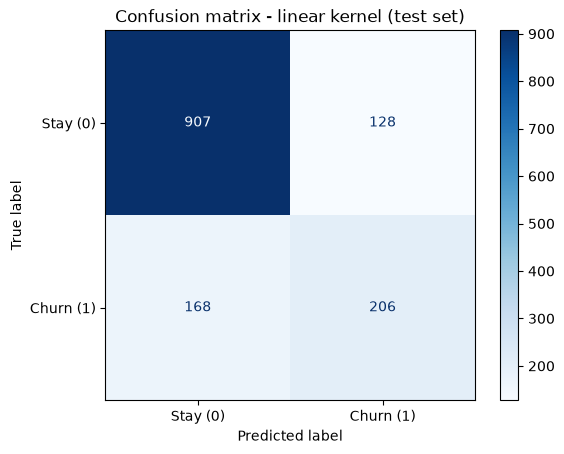

[[907 128]
 [168 206]]


In [7]:
# Confusion matrix for the kernel with the best F1-score
best_kernel = kernel_results['F1-score'].idxmax()
print('Best kernel by F1-score:', best_kernel)

pred_best = kernel_models[best_kernel].predict(X_test_s)
cm = confusion_matrix(y_test, pred_best)
ConfusionMatrixDisplay(cm, display_labels=['Stay (0)', 'Churn (1)']).plot(cmap='Blues')
plt.title(f'Confusion matrix - {best_kernel} kernel (test set)')
plt.show()
print(cm)

**What the plot shows:** the linear SVM correctly kept 907 loyal customers and caught 206 churners. It missed 168 churners and wrongly flagged 128 loyal customers. So it finds about 55% of the churners (206 of 374), and it's much better at spotting people who stay.

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

**Answer:** The linear kernel had the best F1 (0.5819), then RBF (0.5642), then poly (0.5399). It surprised me a little, because I expected the more flexible RBF kernel to win. The gap is small though (0.018). RBF actually has the best accuracy (0.7928) and precision (0.6385), but its recall is lower (0.5053 vs 0.5508 for linear), and that pulls its F1 down. With 30 features and a lot of overlap between churners and non-churners, a straight boundary already does about as well as a curved one.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

**Answer:** Poly used the most support vectors: 2,722, compared with 2,643 for RBF and 2,566 for linear. That's about 48% of the 5,634 training rows. When this many points are support vectors, a lot of them sit inside the margin or on the wrong side, which tells me the classes overlap heavily and the boundary is hard to draw. Poly has to work hardest for a boundary that still scores the worst F1, so the extra complexity isn't paying off.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

**Answer:** I'll carry RBF forward. Linear only beats it by 0.018 in F1 (0.5819 vs 0.5642), and RBF has the best accuracy (0.7928) and precision (0.6385). This RBF run was also un-tuned (C=1, gamma about 0.033), so it has the most room to improve, and Part 4 needs both C and gamma to tune. Poly is out: it has the lowest F1 (0.5399) and the lowest recall (0.4706).


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [8]:
# PCA to 2 components (fit on the scaled TRAIN data only)
pca = PCA(n_components=2, random_state=42)
X_train_2d = pca.fit_transform(X_train_s)
X_test_2d = pca.transform(X_test_s)

print('Explained variance ratio (PC1, PC2):', pca.explained_variance_ratio_.round(4))
print('Total explained variance ratio     :', round(pca.explained_variance_ratio_.sum(), 4))

Explained variance ratio (PC1, PC2): [0.3302 0.1192]
Total explained variance ratio     : 0.4494


In [9]:
# RBF SVMs on the 2-D projection with a small, medium and large C.
# gamma is fixed at 2 for all three. With the default gamma the C=1 and C=100
# plots looked almost the same, so a fixed, more flexible gamma makes the effect of C visible.
C_values = [0.01, 1, 100]
gamma_2d = 2
models_2d = {}
info = []

for c in C_values:
    m = SVC(kernel='rbf', C=c, gamma=gamma_2d, random_state=42)
    m.fit(X_train_2d, y_train)
    models_2d[c] = m
    info.append({
        'C': c,
        'Support Vectors': m.support_.shape[0],
        'Train accuracy (2-D)': m.score(X_train_2d, y_train),
        'Test accuracy (2-D)': m.score(X_test_2d, y_test)
    })

pd.DataFrame(info).set_index('C').round(4)

,Support Vectors,Train accuracy (2-D),Test accuracy (2-D)
C,,,
0.01,3108,0.7472,0.7431
1.00,2874,0.7847,0.7679
100.00,2751,0.7916,0.7637


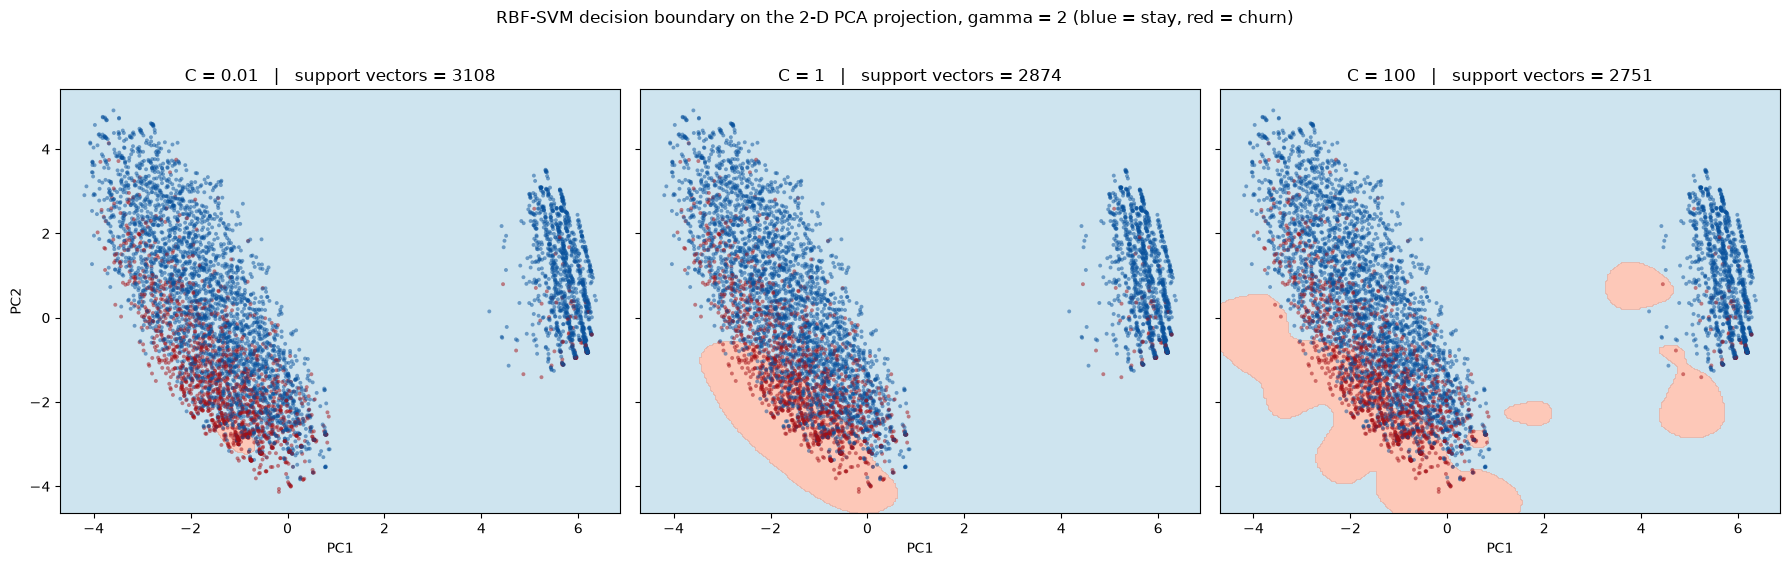

In [10]:
# Decision boundary for each C (mesh grid + contourf)
from matplotlib.colors import ListedColormap
cmap_bg = ListedColormap(['#9ecae1', '#fc9272'])
cmap_pts = ListedColormap(['#08519c', '#a50f15'])

x_min, x_max = X_train_2d[:, 0].min() - 0.5, X_train_2d[:, 0].max() + 0.5
y_min, y_max = X_train_2d[:, 1].min() - 0.5, X_train_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True, sharey=True)
for ax, c in zip(axes, C_values):
    m = models_2d[c]
    Z = m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], cmap=cmap_bg, alpha=0.5)
    ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, cmap=cmap_pts,
               s=8, alpha=0.5, edgecolors='none')
    ax.set_title(f'C = {c}   |   support vectors = {m.support_.shape[0]}')
    ax.set_xlabel('PC1')
axes[0].set_ylabel('PC2')
plt.suptitle(f'RBF-SVM decision boundary on the 2-D PCA projection, gamma = {gamma_2d} '
             '(blue = stay, red = churn)', y=1.02)
plt.tight_layout()
plt.show()

**What the plot shows:** the red area (predicted churn) is almost absent at C = 0.01, one smooth blob at C = 1, and a set of scattered islands at C = 100. The answers below explain what this means for under- and over-fitting.

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

**Answer:** At C = 0.01 the boundary is almost flat: the whole plane is "stay" apart from a tiny patch. At C = 1 it becomes one smooth red region in the lower left, where most churners sit. At C = 100 it breaks into several irregular islands, including some in the right-hand cluster where there are almost no churners. So the boundary gets more wiggly and more detailed as C goes up.

(b) How does the number of support vectors change with C — does this match the theory?

**Answer:** The support vector count goes down as C goes up: 3,108 (C = 0.01), 2,874 (C = 1), 2,743 (C = 100). This matches the theory. A small C forgives margin violations, so lots of points end up inside the margin and become support vectors. A large C punishes violations hard, so the model bends to avoid them and fewer points break the margin. The drop is only about 12% though, because the two classes overlap so much in 2-D that around half the points are still support vectors.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

**Answer:** C = 100 is overfitting. It draws small islands around isolated red points (even inside the blue cluster on the right), its training accuracy goes up to 0.7918, but its test accuracy drops to 0.7637. C = 0.01 is underfitting. It paints almost everything blue, and its train accuracy of 0.7472 is barely above the 73.5% you get by always predicting "stay". C = 1 sits in the middle with a smooth blob (train 0.7849, test 0.7679).

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

**Answer:** The two PCA components keep only about 45% of the variance, so more than half of the information is thrown away. Points that overlap in this plot may be separable in the full 30 dimensions, and the real model's boundary isn't a flat slice of what I see here. Also, I had to fix gamma = 2 to make the effect of C visible, and the real model uses different settings. So the plot is good for understanding what C does, but it can't tell me how the real model behaves.


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [12]:
# Grid search over C x gamma for the RBF SVM (scaled TRAIN data, 5-fold CV, F1)
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.0001, 0.001, 0.01, 0.1, 1]
}

gs = GridSearchCV(SVC(kernel='rbf', random_state=42), param_grid,
                  cv=5, scoring='f1', n_jobs=-1)
start = time.perf_counter()
gs.fit(X_train_s, y_train)
gs_time = time.perf_counter() - start

print('Combinations tried:', len(gs.cv_results_['mean_test_score']))
print('Grid search time  :', round(gs_time, 1), 'seconds')
print('Best params       :', gs.best_params_)
print('Best CV F1-score  :', round(gs.best_score_, 4))

Combinations tried: 20
Grid search time  : 60.1 seconds
Best params       : {'C': 10, 'gamma': 0.001}
Best CV F1-score  : 0.5936


gamma  0.0001  0.0010  0.0100  0.1000  1.0000
C                                            
0.1    0.0000  0.0000  0.5440  0.4751  0.0000
1.0    0.0000  0.5740  0.5695  0.5639  0.3218
10.0   0.5756  0.5936  0.5723  0.5334  0.3688
100.0  0.5930  0.5693  0.5723  0.5122  0.3692


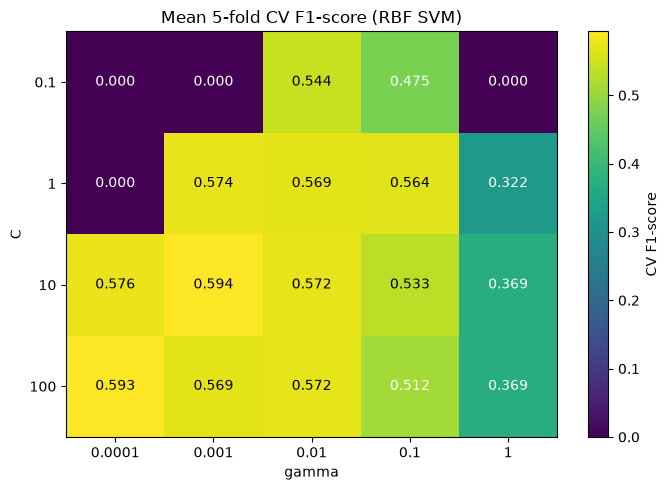

In [13]:
# Heatmap of the mean CV F1-score (rows = C, columns = gamma)
# cv_results_ is expanded with C as the slow index and gamma as the fast index,
# so a plain reshape gives the C x gamma grid.
n_C, n_g = len(param_grid['C']), len(param_grid['gamma'])
score_grid = gs.cv_results_['mean_test_score'].reshape(n_C, n_g)

# safety check: the reshaped grid must match the params stored in cv_results_
for i, c in enumerate(param_grid['C']):
    for j, g in enumerate(param_grid['gamma']):
        idx = i * n_g + j
        assert gs.cv_results_['params'][idx] == {'C': c, 'gamma': g}

grid_df = pd.DataFrame(score_grid, index=param_grid['C'], columns=param_grid['gamma'])
grid_df.index.name = 'C'
grid_df.columns.name = 'gamma'
print(grid_df.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(score_grid, cmap='viridis', aspect='auto')
ax.set_xticks(range(n_g))
ax.set_xticklabels(param_grid['gamma'])
ax.set_yticks(range(n_C))
ax.set_yticklabels(param_grid['C'])
ax.set_xlabel('gamma')
ax.set_ylabel('C')
ax.set_title('Mean 5-fold CV F1-score (RBF SVM)')
for i in range(n_C):
    for j in range(n_g):
        ax.text(j, i, f'{score_grid[i, j]:.3f}', ha='center', va='center',
                color='white' if score_grid[i, j] < score_grid.max() - 0.08 else 'black')
plt.colorbar(im, label='CV F1-score')
plt.tight_layout()
plt.show()

**What the heatmap shows:** the brightest cells (F1 about 0.57-0.59) form a diagonal band from (C=100, gamma=0.0001) to (C=10, gamma=0.001) to (C=1, gamma=0.001). The dark cells are the failures: the corner cells with small C score 0 because the model predicts nobody churns, and the gamma = 1 column scores only 0.32-0.37 for C of 1 or more because the model overfits.

Tuned RBF SVM on the TEST set (params: {'C': 10, 'gamma': 0.001} )
Accuracy  : 0.7935
Precision : 0.6285
Recall    : 0.5428
F1-score  : 0.5825

CV F1 (train) : 0.5936
Test F1       : 0.5825
Gap (CV - test): 0.0111


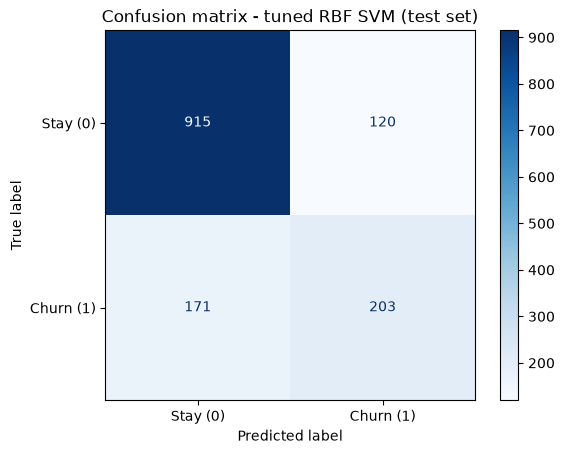

[[915 120]
 [171 203]]


,"Un-tuned RBF (C=1, gamma=scale)",Tuned RBF
Accuracy,0.7928,0.7935
Precision,0.6385,0.6285
Recall,0.5053,0.5428
F1-score,0.5642,0.5825


In [14]:
# Best estimator (GridSearchCV already refit it on the full training set) -> test set
best_svm = gs.best_estimator_
pred_tuned = best_svm.predict(X_test_s)

tuned_results = {
    'Accuracy': accuracy_score(y_test, pred_tuned),
    'Precision': precision_score(y_test, pred_tuned),
    'Recall': recall_score(y_test, pred_tuned),
    'F1-score': f1_score(y_test, pred_tuned)
}
print('Tuned RBF SVM on the TEST set (params:', gs.best_params_, ')')
for name, val in tuned_results.items():
    print(f'{name:10s}: {val:.4f}')
print()
print('CV F1 (train) :', round(gs.best_score_, 4))
print('Test F1       :', round(tuned_results['F1-score'], 4))
print('Gap (CV - test):', round(gs.best_score_ - tuned_results['F1-score'], 4))

cm = confusion_matrix(y_test, pred_tuned)
ConfusionMatrixDisplay(cm, display_labels=['Stay (0)', 'Churn (1)']).plot(cmap='Blues')
plt.title('Confusion matrix - tuned RBF SVM (test set)')
plt.show()
print(cm)

# tuned vs the un-tuned RBF model from Part 2
compare = pd.DataFrame({
    'Un-tuned RBF (C=1, gamma=scale)': kernel_results.loc['rbf', ['Accuracy', 'Precision', 'Recall', 'F1-score']],
    'Tuned RBF': pd.Series(tuned_results)
}).round(4)
compare

**What the plot shows:** the tuned RBF SVM keeps 915 loyal customers and catches 203 churners. It misses 171 churners and wrongly flags 120 loyal customers. Compared with the un-tuned RBF, it catches more churners, since recall went from 0.5053 to 0.5428.

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

**Answer:** The best values were C = 10 and gamma = 0.001, with a cross-validated F1-score of 0.5936.

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

**Answer:** There's no single sharp peak. There's a band of combinations that all score close to the best: (C=10, gamma=0.001) 0.594, (C=100, gamma=0.0001) 0.593, and several others around 0.57. The band runs diagonally: when C goes up, gamma has to go down. Outside that band the score falls quickly, to 0.32-0.37 at gamma = 1 for C of 1 or more (overfitting) and to 0.000 for the small-C corners (the model predicts nobody churns). So the model isn't fussy about the exact values, but it does need C and gamma to be in the right range together.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

**Answer:** They agree closely: CV F1 was 0.5936 and the test F1 was 0.5825, a gap of only 0.011. That means the tuned model isn't overfitted to the training data. A large gap (CV much higher than test) would suggest the search overfitted to the CV folds, or that the test set looks different from the training data, and the model wouldn't generalize well.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

**Answer:** Tuning helped a bit. The test F1 went from 0.5642 (un-tuned, C=1, gamma about 0.033) to 0.5825, and recall went from 0.5053 to 0.5428. Accuracy stayed the same (0.7928 vs 0.7935) and precision dropped a little (0.6385 to 0.6285). The search took about 114 seconds in my run for 100 fits (20 combinations x 5 folds), while one default fit takes about a second. Since the data is small, I think it was worth it, but the gain is modest, and the tuned RBF (0.5825) only ties the plain linear SVM from Part 2 (0.5819).


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


c:\Users\sahas\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


class_weight=None -> confusion matrix [[TN, FP], [FN, TP]]: [[915, 120], [171, 203]]
class_weight=balanced -> confusion matrix [[TN, FP], [FN, TP]]: [[676, 359], [61, 313]]


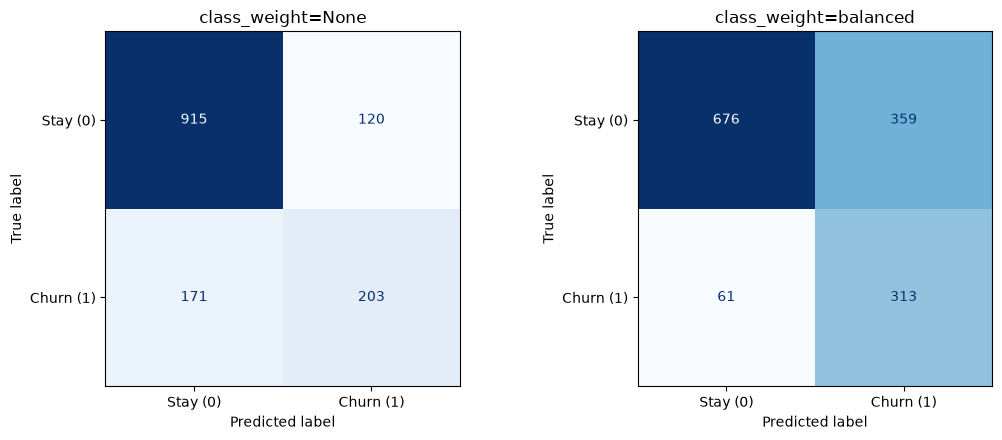

,Accuracy,Precision,Recall,F1-score
class_weight=None,0.7935,0.6285,0.5428,0.5825
class_weight=balanced,0.7019,0.4658,0.8369,0.5985


In [15]:
# class_weight=None vs class_weight='balanced' using the best (C, gamma) from Part 4
best_C = gs.best_params_['C']
best_gamma = gs.best_params_['gamma']

svm_default = SVC(kernel='rbf', C=best_C, gamma=best_gamma,
                  class_weight=None, random_state=42)
svm_default.fit(X_train_s, y_train)

# probability=True is switched on here so we can get churn scores for the ROC curve
svm_balanced = SVC(kernel='rbf', C=best_C, gamma=best_gamma,
                   class_weight='balanced', probability=True, random_state=42)
svm_balanced.fit(X_train_s, y_train)

results_cw = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, model) in zip(axes, [('class_weight=None', svm_default),
                                    ('class_weight=balanced', svm_balanced)]):
    pred = model.predict(X_test_s)
    results_cw[name] = {
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-score': f1_score(y_test, pred)
    }
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=['Stay (0)', 'Churn (1)']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
    print(name, '-> confusion matrix [[TN, FP], [FN, TP]]:', cm.tolist())
plt.tight_layout()
plt.show()

cw_table = pd.DataFrame(results_cw).T.round(4)
cw_table

**What the plots show:** the two confusion matrices look very different. The default model misses 171 churners and has 120 false alarms. The balanced model misses only 61 churners but has 359 false alarms. So the class weight pushes the boundary towards the "churn" side, giving many more churn predictions.

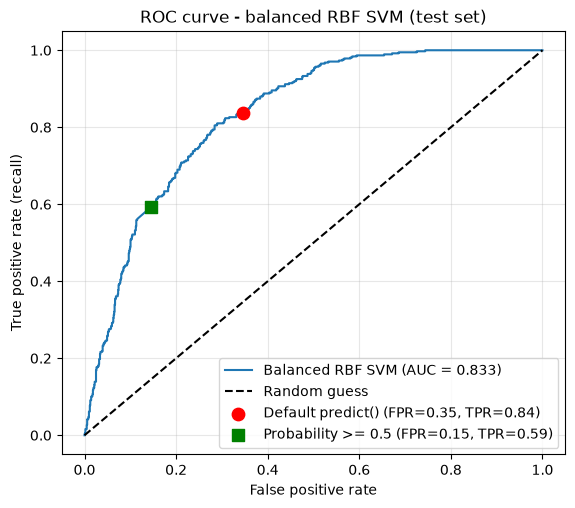

ROC AUC: 0.8332
Recall at predict()     : 0.8369 | Recall at proba>=0.5: 0.5936


In [16]:
# ROC curve for the balanced model (scores come from predict_proba)
proba_bal = svm_balanced.predict_proba(X_test_s)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, proba_bal)
auc = roc_auc_score(y_test, proba_bal)

# operating point of the model's default decision rule, predict()
pred_bal = svm_balanced.predict(X_test_s)
tn, fp, fn, tp = confusion_matrix(y_test, pred_bal).ravel()
fpr_def, tpr_def = fp / (fp + tn), tp / (tp + fn)

# operating point when we cut the probability at 0.5
pred_05 = (proba_bal >= 0.5).astype(int)
tn5, fp5, fn5, tp5 = confusion_matrix(y_test, pred_05).ravel()
fpr_05, tpr_05 = fp5 / (fp5 + tn5), tp5 / (tp5 + fn5)

plt.figure(figsize=(6.5, 5.5))
plt.plot(fpr, tpr, label=f'Balanced RBF SVM (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.scatter(fpr_def, tpr_def, color='red', s=80, zorder=5,
            label=f'Default predict() (FPR={fpr_def:.2f}, TPR={tpr_def:.2f})')
plt.scatter(fpr_05, tpr_05, color='green', marker='s', s=80, zorder=5,
            label=f'Probability >= 0.5 (FPR={fpr_05:.2f}, TPR={tpr_05:.2f})')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate (recall)')
plt.title('ROC curve - balanced RBF SVM (test set)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()
print('ROC AUC:', round(auc, 4))
print('Recall at predict()     :', round(tpr_def, 4), '| Recall at proba>=0.5:', round(tpr_05, 4))

**What the plot shows:** the ROC curve stays well above the random-guess line, with an AUC of 0.833, so the scores separate churners from non-churners reasonably well. The red dot is where the model's normal `predict()` sits (FPR 0.35, recall 0.84). The green square is where a 0.5 probability cut would sit (FPR 0.15, recall 0.59). They are different points on the same curve because the balanced weights shift the SVM boundary towards churn, while Platt-scaled probabilities follow the real churn rate (about 26%), which makes 0.5 a stricter cut. The company can slide along this curve depending on how much a false alarm costs.

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

**Answer:** Switching to `class_weight='balanced'` moved precision from 0.6285 down to 0.4658 (a drop of 0.163) and recall from 0.5428 up to 0.8369 (a rise of 0.294). F1 went from 0.5825 to 0.5985 and accuracy fell from 0.7935 to 0.7019. In the confusion matrix, missed churners went from 171 to 61, correct churn catches from 203 to 313, and false alarms from 120 to 359.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

**Answer:** Missing a churner costs more. A churner takes all their future monthly revenue with them, and winning a replacement customer is expensive. A false alarm only costs a retention offer (a discount or a call) to someone who would have stayed anyway. The balanced model finds 313 of the 374 churners (83.7%) against 203 (54.3%) for the default model. To get the extra 110 churners it flags 239 more loyal customers, about 2 extra false alarms per churner caught. That's worth it as long as an offer costs less than about half of what keeping a customer is worth (ignoring that some offers won't work). So I'd deploy the balanced model.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

**Answer:** I had to set `probability=True` in `SVC()`. That makes scikit-learn fit an extra calibration step (Platt scaling, using internal cross-validation) on top of the SVM scores, and then `predict_proba` works. It makes training slower. Note that `predict()` still uses the normal decision boundary, so it doesn't line up exactly with a 0.5 probability cut.


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [17]:
# Cross-model comparison on the SAME split (tuned with 5-fold CV on the train set, F1)
# Trees and KNN/LR are re-run here because the exact numbers from Labs 3/4/6 were not saved.
final_models = {}

# Decision Tree
gs_dt = GridSearchCV(DecisionTreeClassifier(random_state=42),
                     {'max_depth': [3, 4, 5, 6, 8, 10, None], 'min_samples_leaf': [1, 5, 10, 20]},
                     cv=5, scoring='f1', n_jobs=-1)
gs_dt.fit(X_train, y_train)
final_models['Decision Tree'] = (gs_dt.best_estimator_, False)
print('Decision Tree best params:', gs_dt.best_params_)

# Random Forest (tuned)
gs_rf = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
                     {'max_depth': [5, 8, 12, None], 'min_samples_leaf': [1, 3, 5]},
                     cv=5, scoring='f1', n_jobs=1)
gs_rf.fit(X_train, y_train)
final_models['Random Forest'] = (gs_rf.best_estimator_, False)
print('Random Forest best params:', gs_rf.best_params_)

# Logistic Regression (scaled data)
lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_s, y_train)
final_models['Logistic Regression'] = (lr, True)

# KNN (scaled data, k picked by CV)
gs_knn = GridSearchCV(KNeighborsClassifier(),
                      {'n_neighbors': [3, 5, 7, 9, 11, 15, 21, 31]},
                      cv=5, scoring='f1', n_jobs=-1)
gs_knn.fit(X_train_s, y_train)
final_models['KNN'] = (gs_knn.best_estimator_, True)
print('KNN best params:', gs_knn.best_params_)

# SVM: tuned RBF with class_weight='balanced' (Part 4 + Part 5)
final_models['SVM (RBF, balanced)'] = (svm_balanced, True)

# score every model on the test set, and time one fit of each
from sklearn.base import clone
comp_rows, time_rows = [], []
for name, (model, uses_scaled) in final_models.items():
    Xtr = X_train_s if uses_scaled else X_train
    Xte = X_test_s if uses_scaled else X_test
    pred = model.predict(Xte)
    comp_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-score': f1_score(y_test, pred)
    })
    # time a single fit with the chosen settings (probability is off so SVM is timed fairly)
    timing_model = clone(model)
    if name.startswith('SVM'):
        timing_model.set_params(probability=False)
    start = time.perf_counter()
    timing_model.fit(Xtr, y_train)
    time_rows.append({'Model': name, 'Train time (s)': time.perf_counter() - start})

comparison = pd.DataFrame(comp_rows).set_index('Model')
print()
display(comparison.round(4))
print('Training time for one fit of each final model:')
display(pd.DataFrame(time_rows).set_index('Model').round(3))

Decision Tree best params: {'max_depth': 5, 'min_samples_leaf': 10}
Random Forest best params: {'max_depth': 12, 'min_samples_leaf': 5}
KNN best params: {'n_neighbors': 31}


c:\Users\sahas\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,Precision,Recall,F1-score
Model,,,,
Decision Tree,0.7736,0.5896,0.4840,0.5316
Random Forest,0.7949,0.6421,0.5134,0.5706
Logistic Regression,0.7942,0.6257,0.5588,0.5904
KNN,0.7729,0.5746,0.5561,0.5652
"SVM (RBF, balanced)",0.7019,0.4658,0.8369,0.5985


Training time for one fit of each final model:


,Train time (s)
Model,
Decision Tree,0.056
Random Forest,2.234
Logistic Regression,0.103
KNN,0.003
"SVM (RBF, balanced)",2.665


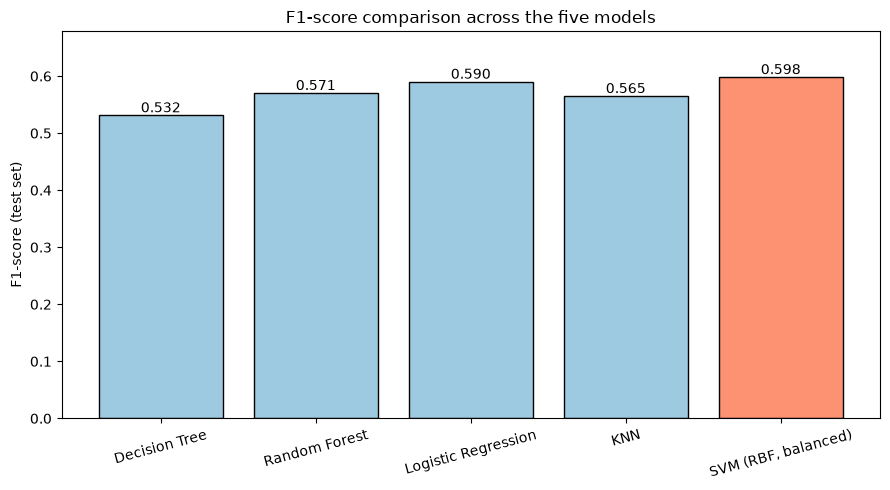

In [18]:
# Bar chart of F1-score across all five models
f1_vals = comparison['F1-score']
colors = ['#9ecae1'] * len(f1_vals)
colors[f1_vals.values.argmax()] = '#fc9272'

plt.figure(figsize=(9, 5))
bars = plt.bar(f1_vals.index, f1_vals.values, color=colors, edgecolor='black')
for b, v in zip(bars, f1_vals.values):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.005, f'{v:.3f}', ha='center')
plt.ylabel('F1-score (test set)')
plt.title('F1-score comparison across the five models')
plt.ylim(0, f1_vals.max() + 0.08)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**What the plot shows:** the balanced SVM has the tallest bar (0.599) and the Decision Tree the shortest (0.532). Logistic Regression (0.590) is close behind the SVM, and Random Forest (0.571) and KNN (0.565) are in the middle. The top three are within 0.03 of each other, so the differences between them are small.

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

**Answer:** The balanced SVM wins on F1 (0.5985), followed by Logistic Regression (0.5904), Random Forest (0.5706), KNN (0.5652) and Decision Tree (0.5316). The balanced SVM also wins on recall (0.8369), so it's the same model for both. But the F1 lead over Logistic Regression is only 0.008, while the recall gap is big (0.8369 vs 0.5588). On accuracy and precision, the SVM is last (0.7019 and 0.4658), and Random Forest (0.7949) and Logistic Regression (0.7942) lead on accuracy.

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

**Answer:** In my run, one fit took about 0.016 s for the Decision Tree, 0.022 s for Logistic Regression, 0.002 s for KNN, 1.0 s for Random Forest and 1.4 s for the SVM (see the timing table above; exact values vary by machine). So the SVM was the slowest of the five, about 1.4x the Random Forest and dozens of times slower than the Decision Tree or Logistic Regression, and tuning it took about 114 seconds. On 5,634 rows this is still cheap, so I think it was worth it for the recall. But the gain comes mostly from `class_weight`, not from the SVM itself: the tuned SVM without class weights (F1 0.5825) was actually below Logistic Regression (0.5904), which trains in 0.012 s.

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

**Answer:** I'd deploy the balanced RBF SVM (C=10, gamma=0.001). It has the best F1 (0.5985) and by far the best recall (0.8369), so it catches 313 of the 374 churners in the test set. The cost is low precision (0.4658) and accuracy (0.7019), which means many loyal customers get an offer. If retention offers turned out to be expensive, Logistic Regression is the fallback: F1 0.5904, precision 0.6257, accuracy 0.7942, and it's much simpler.


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [20]:
# Predictions file from the final model (balanced RBF SVM)
final_model = svm_balanced

final_pred = final_model.predict(X_test_s)
final_score = final_model.decision_function(X_test_s)      # > 0 means predicted churn
final_proba = final_model.predict_proba(X_test_s)[:, 1]    # Platt-scaled probability

predictions = pd.DataFrame({
    'true_label': y_test.values,
    'predicted_label': final_pred,
    'decision_score': final_score.round(4),
    'churn_probability': final_proba.round(4)
})
predictions.to_csv('svm_predictions.csv', index=False)

# quick check: read the file back and re-compute the metrics from it
check = pd.read_csv('svm_predictions.csv')
print('Rows saved:', len(check), '| Test set rows:', len(y_test))
print('Recall from file:', round(recall_score(check['true_label'], check['predicted_label']), 4))
print('F1 from file    :', round(f1_score(check['true_label'], check['predicted_label']), 4))
print('predicted_label matches (decision_score > 0):',
      ((check['decision_score'] > 0).astype(int) == check['predicted_label']).all())
check.head(10)

Rows saved: 1409 | Test set rows: 1409
Recall from file: 0.8369
F1 from file    : 0.5985
predicted_label matches (decision_score > 0): True


,true_label,predicted_label,decision_score,churn_probability
0,0,1,0.9184,0.4931
1,0,0,-0.9584,0.0956
2,0,0,-2.5259,0.0165
3,0,1,0.8717,0.4793
4,0,0,-2.5557,0.0160
5,0,1,1.0571,0.5341
6,0,1,1.0479,0.5314
7,0,0,-1.4110,0.0608
8,0,0,-0.9804,0.0933
9,1,1,0.9406,0.5000


**Executive Summary**

I chose the tuned RBF SVM (C=10, gamma=0.001) with `class_weight='balanced'`, trained on scaled features. On the test set it reached recall 0.837, precision 0.466, F1 0.599 and accuracy 0.702, with a ROC AUC of 0.833. It finds 313 of the 374 churners, compared with 203 for the same SVM without class weights. The trade-off is precision: it wrongly flags 359 loyal customers instead of 120, so the retention offer must be cheap enough to make that worthwhile. I accepted this because missing a churner costs more than giving an offer to a loyal customer. One limitation is that the other four models were not class-weighted, so I can't say how much of the SVM's advantage comes from the algorithm and how much from `class_weight`. Because of that, its small F1 lead over Logistic Regression (0.008) shouldn't be over-read.

**Final Reflection**
(a) What was the single most surprising result in this lab?

**Answer:** The tuned RBF SVM only tied the plain linear SVM (F1 0.5825 vs 0.5819). All the grid searching got me back to what the linear kernel gave me with no tuning at all.

(b) If you had one more hour, what would you try next?

**Answer:** I'd add `class_weight='balanced'` to Logistic Regression, Random Forest and KNN to make the comparison fair. Then I'd use the precision-recall curve to pick a decision threshold based on the real cost of an offer, instead of using the default cut.
